# Comparación de modelos clásicos: KNN y SVM

**Grupo G7 · Luis Anchundia · 22/oct/2026**

Se usan solo los **1.827 ciclos de entrenamiento** y los cinco pliegues por `group_id` del proyecto. El conjunto de prueba no se consulta. Todos los modelos usan `crear_pipeline` (escalado, filtro de correlación y estimador). Dayron y José aportarán Random Forest, MLP y metaheurística a la tabla común.

La búsqueda y la evaluación de la configuración ganadora emplean los mismos pliegues: la CV informada describe la configuración elegida, pero puede ser optimista por selección de hiperparámetros. La única evaluación final independiente será la prueba reservada, después de elegir el modelo entre los tres integrantes.

In [1]:
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import scipy
import sklearn
from scipy.stats import loguniform
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from ic_g7 import config
from ic_g7.datos import cargar_entrenamiento
from ic_g7.evaluacion import crear_cv, validar_cruzado
from ic_g7.pipeline import crear_pipeline

warnings.filterwarnings("ignore", message="The `probability` parameter was deprecated",
                        category=FutureWarning)
X, y, grupos = cargar_entrenamiento()
print("Entrenamiento:", X.shape, "| grupos:", grupos.nunique())
print("Clases:", y.value_counts().sort_index().to_dict())
config.DIR_REPORTES.mkdir(parents=True, exist_ok=True)
dir_figuras = config.DIR_REPORTES / "figuras"
dir_figuras.mkdir(parents=True, exist_ok=True)

Entrenamiento: (1827, 68) | grupos: 111
Clases: {0: 686, 1: 317, 2: 317, 3: 507}


## 1. Líneas base

`most_frequent` y `stratified` ofrecen dos referencias sencillas. `DummyClassifier` va dentro del mismo `Pipeline`, aunque ignora las variables de los sensores.

In [2]:
filas = []
pliegues_modelos = []
for estrategia in ("most_frequent", "stratified"):
    nombre = f"Dummy({estrategia})"
    modelo = crear_pipeline(DummyClassifier(
        strategy=estrategia, random_state=config.RANDOM_STATE
    ))
    fila, pliegues = validar_cruzado(
        modelo, X, y, grupos, nombre,
        {"strategy": estrategia, "umbral_correlacion": 0.995},
    )
    filas.append(fila)
    pliegues_modelos.append(pliegues.assign(modelo=nombre))
display(pd.DataFrame(filas))

,modelo,hiperparámetros,F1_macro_CV (media±std),exactitud_CV,ROC_AUC_CV,t_entrenamiento,t_inferencia
0,Dummy(most_frequent),"{'strategy': 'most_frequent', 'umbral_correlac...",0.1289 ± 0.0388,0.3625 ± 0.1459,0.5000 ± 0.0000,0.016219,0.001526
1,Dummy(stratified),"{'strategy': 'stratified', 'umbral_correlacion...",0.2498 ± 0.0280,0.2781 ± 0.0262,0.5104 ± 0.0169,0.011958,0.001635


## 2. Búsqueda de KNN

Se evalúan los tres hiperparámetros exigidos por el contrato: número de vecinos, ponderación y distancia. La rejilla tiene **36 combinaciones** y mantiene el preprocesamiento dentro de cada ajuste de CV.

In [3]:
rejilla_knn = {
    "modelo__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41],
    "modelo__weights": ["uniform", "distance"],
    "modelo__metric": ["euclidean", "manhattan"],
}
busqueda_knn = GridSearchCV(
    crear_pipeline(KNeighborsClassifier()), rejilla_knn,
    scoring="f1_macro", cv=crear_cv(), n_jobs=1, refit=True,
    return_train_score=False,
)
busqueda_knn.fit(X, y, groups=grupos)
print("Mejores parámetros:", busqueda_knn.best_params_)
print("F1 macro en búsqueda:", round(busqueda_knn.best_score_, 4))
display(pd.DataFrame(busqueda_knn.cv_results_)[
    ["mean_test_score", "std_test_score", "param_modelo__n_neighbors",
     "param_modelo__weights", "param_modelo__metric"]
].sort_values("mean_test_score", ascending=False).head(10).round(4))

Mejores parámetros: {'modelo__metric': 'manhattan', 'modelo__n_neighbors': 11, 'modelo__weights': 'distance'}
F1 macro en búsqueda: 0.5275


,mean_test_score,std_test_score,param_modelo__n_neighbors,param_modelo__weights,param_modelo__metric
27,0.5275,0.1069,11,distance,manhattan
25,0.5259,0.1042,9,distance,manhattan
20,0.5243,0.1066,5,uniform,manhattan
21,0.5227,0.1069,5,distance,manhattan
23,0.5215,0.1043,7,distance,manhattan
22,0.5214,0.1047,7,uniform,manhattan
26,0.5201,0.1087,11,uniform,manhattan
24,0.5200,0.1104,9,uniform,manhattan
18,0.5191,0.0922,3,uniform,manhattan
19,0.5185,0.0964,3,distance,manhattan


## 3. Búsqueda de SVM con núcleo RBF

Se muestrean **30 combinaciones** de `C` y `gamma` en escala logarítmica con la semilla compartida. `probability=True` sigue el contrato y permite ROC-AUC y la futura interfaz; en scikit-learn 1.9 está marcado como obsoleto y habrá que revisar esa elección al actualizar dependencias.

In [4]:
distribucion_svm = {
    "modelo__C": loguniform(1e-2, 1e3),
    "modelo__gamma": loguniform(1e-4, 1),
}
busqueda_svm = RandomizedSearchCV(
    crear_pipeline(SVC(kernel="rbf", probability=True,
                       random_state=config.RANDOM_STATE)),
    distribucion_svm, n_iter=30, scoring="f1_macro", cv=crear_cv(),
    n_jobs=1, refit=True, random_state=config.RANDOM_STATE,
    return_train_score=False,
)
busqueda_svm.fit(X, y, groups=grupos)
print("Mejores parámetros:", busqueda_svm.best_params_)
print("F1 macro en búsqueda:", round(busqueda_svm.best_score_, 4))
display(pd.DataFrame(busqueda_svm.cv_results_)[
    ["mean_test_score", "std_test_score", "param_modelo__C", "param_modelo__gamma"]
].sort_values("mean_test_score", ascending=False).head(10).round(4))

Mejores parámetros: {'modelo__C': np.float64(45.70563099801453), 'modelo__gamma': np.float64(0.024810409748678097)}
F1 macro en búsqueda: 0.7674


,mean_test_score,std_test_score,param_modelo__C,param_modelo__gamma
1,0.7674,0.0870,45.7056,0.0248
19,0.7168,0.0804,26.3733,0.0058
4,0.6799,0.1029,10.1292,0.0680
6,0.6794,0.0914,145.2825,0.0007
25,0.6532,0.1075,704.5684,0.1260
17,0.6323,0.1094,673.2249,0.1712
12,0.6243,0.1039,1.9070,0.1383
26,0.5678,0.0838,498.3044,0.3796
27,0.5409,0.0687,9.7611,0.4870
0,0.4581,0.0432,0.7459,0.6351


## 4. Tabla común y variación entre pliegues

`validar_cruzado` produce las columnas acordadas. `t_entrenamiento` es el tiempo medio de ajuste por pliegue; `t_inferencia` es el tiempo medio de `predict_proba` para el lote de validación, en segundos. `resultados.csv` contiene **por ahora** las dos líneas base, KNN y SVM. Luis incorporará las filas de RF, MLP y GA cuando sus responsables las entreguen, sin inventar resultados.

In [5]:
modelos_ajustados = {
    "KNN ajustado": (busqueda_knn.best_estimator_, busqueda_knn.best_params_),
    "SVM RBF ajustada": (busqueda_svm.best_estimator_, busqueda_svm.best_params_),
}
for nombre, (modelo, parametros) in modelos_ajustados.items():
    parametros_legibles = {clave: valor.item() if isinstance(valor, np.generic) else valor
                          for clave, valor in parametros.items()}
    fila, pliegues = validar_cruzado(modelo, X, y, grupos, nombre, parametros_legibles)
    filas.append(fila)
    pliegues_modelos.append(pliegues.assign(modelo=nombre))
resultados = pd.DataFrame(filas)
resultados.to_csv(config.DIR_REPORTES / "resultados.csv", index=False)
por_pliegue = pd.concat(pliegues_modelos, ignore_index=True)
por_pliegue.to_csv(config.DIR_REPORTES / "pliegues_luis.csv", index=False)
display(resultados)
display(por_pliegue)

,modelo,hiperparámetros,F1_macro_CV (media±std),exactitud_CV,ROC_AUC_CV,t_entrenamiento,t_inferencia
0,Dummy(most_frequent),"{'strategy': 'most_frequent', 'umbral_correlac...",0.1289 ± 0.0388,0.3625 ± 0.1459,0.5000 ± 0.0000,0.016219,0.001526
1,Dummy(stratified),"{'strategy': 'stratified', 'umbral_correlacion...",0.2498 ± 0.0280,0.2781 ± 0.0262,0.5104 ± 0.0169,0.011958,0.001635
2,KNN ajustado,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5275 ± 0.1069,0.5162 ± 0.1486,0.7915 ± 0.0848,0.011066,0.010739
3,SVM RBF ajustada,"{'modelo__C': 45.70563099801453, 'modelo__gamm...",0.7674 ± 0.0870,0.7662 ± 0.0922,0.9379 ± 0.0459,0.193868,0.013521


,pliegue,f1_macro,exactitud,roc_auc,modelo
0,0,0.175841,0.542453,0.500000,Dummy(most_frequent)
1,1,0.079882,0.190141,0.500000,Dummy(most_frequent)
2,2,0.173469,0.531250,0.500000,Dummy(most_frequent)
3,3,0.111717,0.287719,0.500000,Dummy(most_frequent)
4,4,0.103448,0.260870,0.500000,Dummy(most_frequent)
5,0,0.221362,0.271226,0.492118,Dummy(stratified)
6,1,0.235821,0.244131,0.508204,Dummy(stratified)
7,2,0.241433,0.300481,0.508800,Dummy(stratified)
8,3,0.247597,0.259649,0.500700,Dummy(stratified)
9,4,0.302971,0.315217,0.541955,Dummy(stratified)


## 5. Errores por clase y matrices de confusión

Las predicciones fuera de pliegue de las configuraciones elegidas permiten describir confusiones entre 90, 100, 115 y 130 bar. Como la selección de hiperparámetros también se hizo en entrenamiento, estos resultados son descriptivos y no sustituyen la prueba final.

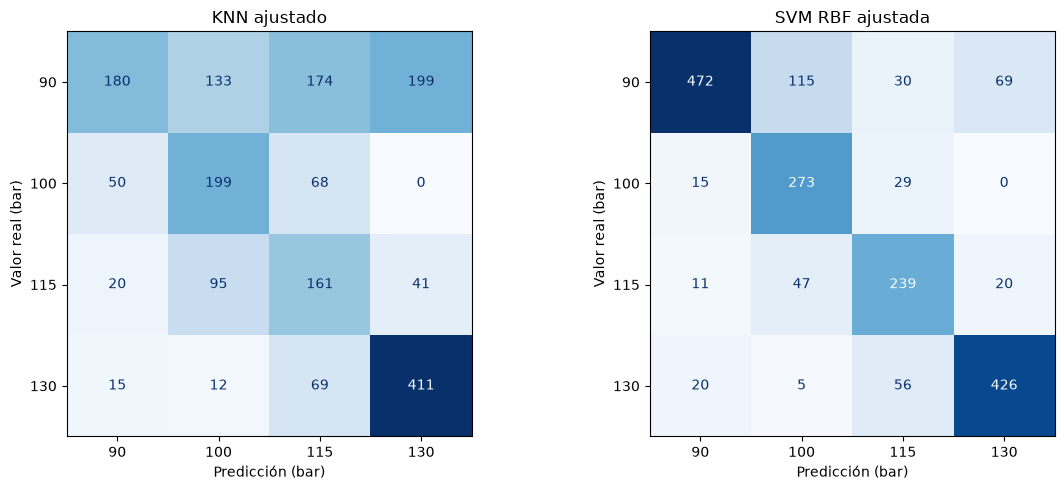

,modelo,clase_bar,precision,recall,f1,soporte
0,KNN ajustado,90,0.679,0.262,0.379,686
1,KNN ajustado,100,0.453,0.628,0.526,317
2,KNN ajustado,115,0.341,0.508,0.408,317
3,KNN ajustado,130,0.631,0.811,0.710,507
4,SVM RBF ajustada,90,0.911,0.688,0.784,686
5,SVM RBF ajustada,100,0.620,0.861,0.721,317
6,SVM RBF ajustada,115,0.675,0.754,0.712,317
7,SVM RBF ajustada,130,0.827,0.840,0.834,507


In [6]:
etiquetas = sorted(config.NOMBRE_CLASE)
barras = [bar for bar, clase in sorted(config.CLASE_POR_OBJETIVO.items(),
                                      key=lambda par: par[1])]
metricas_clase = []
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, (modelo, _)) in zip(ejes, modelos_ajustados.items()):
    predicciones = cross_val_predict(
        modelo, X, y, groups=grupos, cv=crear_cv(), method="predict", n_jobs=1
    )
    matriz = confusion_matrix(y, predicciones, labels=etiquetas)
    ConfusionMatrixDisplay(matriz, display_labels=barras).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set(title=nombre, xlabel="Predicción (bar)", ylabel="Valor real (bar)")
    reporte = classification_report(y, predicciones, labels=etiquetas,
                                     output_dict=True, zero_division=0)
    for clase, bar in zip(etiquetas, barras):
        metricas_clase.append({
            "modelo": nombre, "clase_bar": bar,
            "precision": reporte[str(clase)]["precision"],
            "recall": reporte[str(clase)]["recall"],
            "f1": reporte[str(clase)]["f1-score"],
            "soporte": int(reporte[str(clase)]["support"]),
        })
plt.tight_layout()
fig.savefig(dir_figuras / "matrices_confusion_luis.png", dpi=160,
            bbox_inches="tight")
plt.show()
tabla_clases = pd.DataFrame(metricas_clase)
tabla_clases.to_csv(config.DIR_REPORTES / "metricas_clase_luis.csv", index=False)
display(tabla_clases.round(3))

## 6. Interpretación, reproducibilidad y límites

- La SVM RBF ajustada obtiene F1 macro de CV **0,767 ± 0,087**, frente a **0,528 ± 0,107** de KNN ajustado y **0,250 ± 0,028** de la mejor línea base (`Dummy(stratified)`). Son resultados de entrenamiento y no establecen aún el modelo final: faltan Random Forest, MLP y la comparación del algoritmo genético.
- En predicciones fuera de pliegue de la configuración elegida, la SVM recupera 68,8 % de los ciclos de 90 bar; algunos se confunden con 100 bar. Ese error es relevante porque 90 bar representa el mayor deterioro. KNN solo recupera 26,2 % de esa clase. Debe discutirse con más detalle al elegir el modelo final.
- La tabla y las matrices pueden ser **optimistas** porque se eligieron hiperparámetros con los mismos pliegues de entrenamiento. La prueba reservada se consulta una sola vez después de la selección conjunta.
- La partición y la semilla provienen de `config.py`. Se anotan versiones y hardware para el informe. Las clases minoritarias y los tres grupos muy grandes explican parte de la variación entre pliegues; se publican sus valores individuales.
- La tabla debe completarse con los modelos de Dayron y José antes de seleccionar uno solo. El prototipo final y la evaluación en prueba aún no forman parte de este notebook.

In [7]:
entorno = pd.Series({
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.uname().processor,
    "cpu_logicos": psutil.cpu_count(logical=True),
    "ram_gib": round(psutil.virtual_memory().total / 1024**3, 1),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
    "semilla": config.RANDOM_STATE,
    "pliegues": config.N_PLIEGUES,
})
display(entorno.to_frame("valor"))
entorno.to_csv(config.DIR_REPORTES / "entorno_luis.csv", header=["valor"])

,valor
sistema,Windows-11-10.0.26200-SP0
procesador,"Intel64 Family 6 Model 140 Stepping 1, Genuine..."
cpu_logicos,8
ram_gib,11.8
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
scikit_learn,1.9.1
semilla,42
